# 01 – Data preparation and exploration

In this notebook we:
1. Load all Oslo Bysykkel trips for 2025 (one CSV per month).
2. Clean the data (remove obviously wrong trips).
3. Look at the data with some simple plots (exploratory data analysis).
4. Build a table with **one row per station per hour**, with number of departures, arrivals and the weather.
5. Save the tables so the other notebooks can use them.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = Path("../report/figures")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the trips

In [2]:
columns_to_use = [
    "started_at", "ended_at", "duration",
    "start_station_id", "start_station_name", "start_station_latitude", "start_station_longitude",
    "end_station_id", "end_station_name", "end_station_latitude", "end_station_longitude",
]

files = sorted((DATA_DIR / "bysykkel" / "raw").glob("*.csv"))
trips = pd.concat([pd.read_csv(f, usecols=columns_to_use) for f in files], ignore_index=True)

# Timestamps in the files are in UTC
trips["started_at"] = pd.to_datetime(trips["started_at"], format="ISO8601")
trips["ended_at"] = pd.to_datetime(trips["ended_at"], format="ISO8601")

print("Number of trips:", len(trips))
print("Number of start stations:", trips["start_station_id"].nunique())
trips.head()

Number of trips: 1113904
Number of start stations: 272


,started_at,ended_at,duration,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude
0,2025-01-01 04:37:39.287000+00:00,2025-01-01 04:49:08.139000+00:00,688,441,Vippetangen øst,59.903989,10.741077,390,Saga Kino,59.914240,10.732771
1,2025-01-01 04:44:32.058000+00:00,2025-01-01 04:51:45.817000+00:00,433,535,Uranienborgveien,59.920042,10.726634,478,Jernbanetorget,59.911901,10.749929
2,2025-01-01 05:06:52.481000+00:00,2025-01-01 05:11:28.880000+00:00,276,521,Jess Carlsens gate,59.918636,10.752394,2328,The Hub,59.912522,10.750910
3,2025-01-01 05:22:23.200000+00:00,2025-01-01 05:28:45.298000+00:00,382,480,Helga Helgesens plass,59.912111,10.766194,735,Oslo Hospital,59.903213,10.767344
4,2025-01-01 06:05:12.184000+00:00,2025-01-01 06:08:39.238000+00:00,207,507,Jens Bjelkes Gate,59.919147,10.764130,2328,The Hub,59.912522,10.750910


## 2. Clean the data

- Trips shorter than 60 seconds are most likely someone taking a bike out and putting it right back.
- Trips longer than 3 hours are rare and probably bikes that were not docked correctly.

In [4]:
too_short = trips["duration"] < 60
too_long = trips["duration"] > 3 * 60 * 60

print("Too short:", too_short.sum())
print("Too long: ", too_long.sum())

trips = trips[~too_short & ~too_long].reset_index(drop=True)
print("Trips left:", len(trips))

Too short: 8
Too long:  345
Trips left: 1113551


## 3. Load the weather

The weather was downloaded with `data/scripts/import_weather.py`. The hourly weather is in UTC, just like the trips.

In [5]:
weather_hourly = pd.read_csv(DATA_DIR / "weather" / "oslo_weather_hourly.csv")
weather_hourly["time"] = pd.to_datetime(weather_hourly["time"])

weather_daily = pd.read_csv(DATA_DIR / "weather" / "oslo_weather_daily.csv")
weather_daily["date"] = pd.to_datetime(weather_daily["date"])

weather_hourly.head()

,time,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,snow_depth,cloud_cover,sunshine_duration,wind_speed_10m,wind_gusts_10m,weather_code
0,2025-01-01 00:00:00+00:00,-3.9,85,0.0,0.0,0.00,0.07,100,0.0,5.50,11.6,3
1,2025-01-01 01:00:00+00:00,-3.9,87,0.0,0.0,0.00,0.07,100,0.0,4.41,9.5,3
2,2025-01-01 02:00:00+00:00,-4.2,86,0.1,0.0,0.07,0.07,100,0.0,4.54,9.5,71
3,2025-01-01 03:00:00+00:00,-4.5,86,0.1,0.0,0.07,0.07,100,0.0,3.79,9.4,71
4,2025-01-01 04:00:00+00:00,-4.9,87,0.2,0.0,0.14,0.07,100,0.0,4.14,8.6,71


## 4. Exploratory data analysis

We use **local Oslo time** for everything that has to do with time of day, because people's routines follow local time (and summer time).

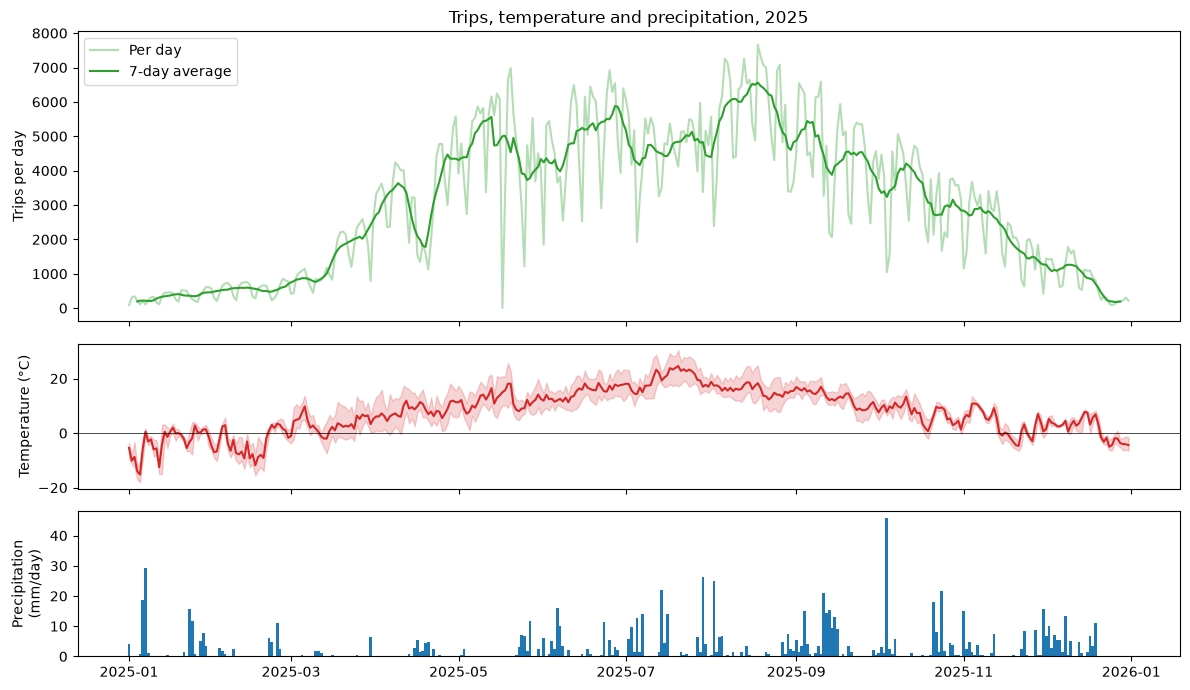

In [6]:
trips["local_start"] = trips["started_at"].dt.tz_convert("Europe/Oslo")
trips["date"] = trips["local_start"].dt.normalize().dt.tz_localize(None)
trips["hour"] = trips["local_start"].dt.hour
trips["is_weekend"] = trips["local_start"].dt.weekday >= 5

daily = trips.groupby("date").size().rename("trips").reset_index()
daily = daily.merge(weather_daily, on="date", how="left")

# Three panels on top of each other, sharing the same time axis
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 7), sharex=True, height_ratios=[2, 1, 1])

ax1.plot(daily["date"], daily["trips"], color="tab:green", alpha=0.35, label="Per day")
ax1.plot(daily["date"], daily["trips"].rolling(7, center=True).mean(), color="tab:green", label="7-day average")
ax1.set_ylabel("Trips per day")
ax1.legend(loc="upper left")
ax1.set_title("Trips, temperature and precipitation, 2025")

ax2.fill_between(daily["date"], daily["temperature_2m_min"], daily["temperature_2m_max"], color="tab:red", alpha=0.2)
ax2.plot(daily["date"], daily["temperature_2m_mean"], color="tab:red")
ax2.axhline(0, color="black", linewidth=0.5)
ax2.set_ylabel("Temperature (°C)")

# precipitation_sum = rain + melted snow in mm
ax3.bar(daily["date"], daily["precipitation_sum"], color="tab:blue", width=1)
ax3.set_ylabel("Precipitation\n(mm/day)")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_trips_per_day.png", dpi=150)
plt.show()

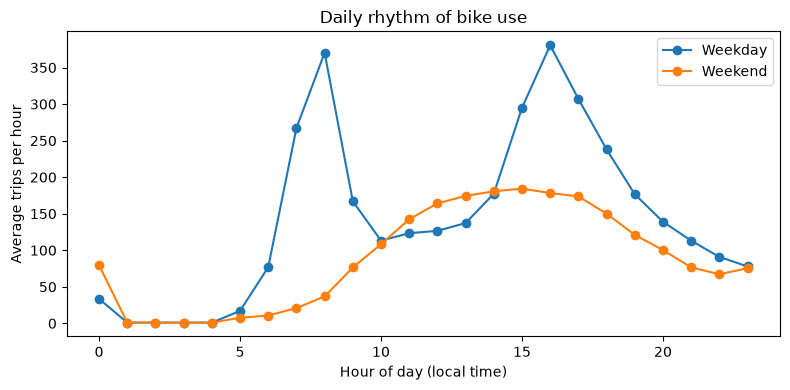

In [7]:
# Average number of trips per hour of the day, weekdays vs weekends
trips_per_hour = trips.groupby(["date", "hour", "is_weekend"]).size().rename("trips").reset_index()
avg_per_hour = trips_per_hour.groupby(["is_weekend", "hour"])["trips"].mean().unstack(0)

ax = avg_per_hour.plot(figsize=(8, 4), marker="o")
ax.set_xlabel("Hour of day (local time)")
ax.set_ylabel("Average trips per hour")
ax.legend(["Weekday", "Weekend"])
ax.set_title("Daily rhythm of bike use")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_trips_per_hour.png", dpi=150)
plt.show()

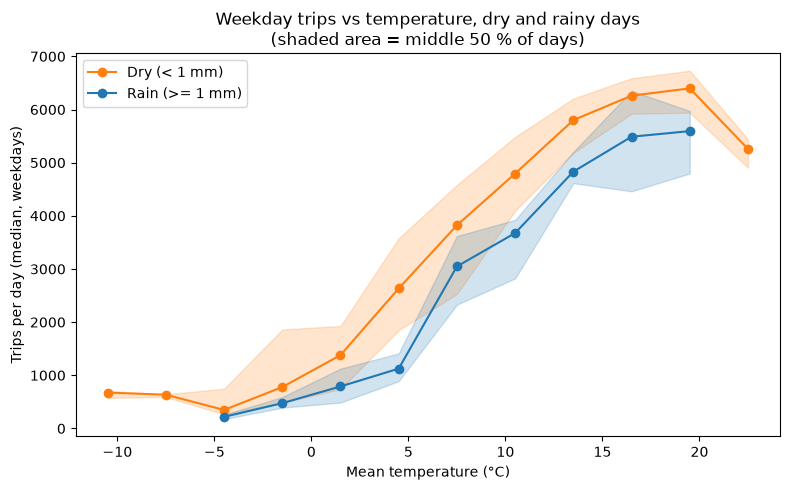

In [8]:
# Trips per day vs temperature. Only weekdays, so the weekend drop does not blur the picture.
# Days are grouped in 3 °C bins; the median is used so single odd days (holidays) do not pull the line.
weekdays = daily[daily["date"].dt.weekday < 5].copy()
weekdays["temp_bin"] = (weekdays["temperature_2m_mean"] // 3) * 3 + 1.5
weekdays["rainy"] = weekdays["precipitation_sum"] >= 1

plt.figure(figsize=(8, 5))
for is_rainy, label, color in [(False, "Dry (< 1 mm)", "tab:orange"), (True, "Rain (>= 1 mm)", "tab:blue")]:
    group = weekdays[weekdays["rainy"] == is_rainy].groupby("temp_bin")["trips"]
    summary = group.agg(["median", "count"])
    summary = summary[summary["count"] >= 3]  # skip bins with too few days
    q25 = group.quantile(0.25)[summary.index]
    q75 = group.quantile(0.75)[summary.index]
    plt.plot(summary.index, summary["median"], marker="o", color=color, label=label)
    plt.fill_between(summary.index, q25, q75, color=color, alpha=0.2)

plt.xlabel("Mean temperature (°C)")
plt.ylabel("Trips per day (median, weekdays)")
plt.title("Weekday trips vs temperature, dry and rainy days\n(shaded area = middle 50 % of days)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_trips_vs_temperature.png", dpi=150)
plt.show()

### Rain within the day

A rainy day can still have dry hours, so daily rain totals hide much of the effect of rain. Here we compare **hours** with and without rain, only on weekdays from May to September, so that season and weekday do not mix into the comparison.

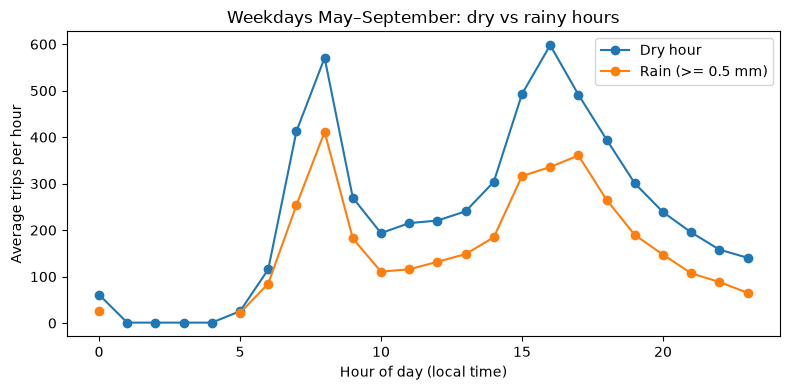

Number of rainy hours used: 151
Daytime (07-20) trips in rainy hours compared with dry hours: 0.63


In [11]:
city_hourly = trips.groupby(trips["started_at"].dt.floor("h")).size().rename("trips").reset_index()
city_hourly = city_hourly.rename(columns={"started_at": "time"})
city_hourly = city_hourly.merge(weather_hourly[["time", "precipitation"]], on="time", how="left")

local = city_hourly["time"].dt.tz_convert("Europe/Oslo")
city_hourly["hour"] = local.dt.hour
summer_weekday = local.dt.month.between(5, 9) & (local.dt.weekday < 5)
city_hourly["wet"] = city_hourly["precipitation"] >= 0.5  # at least 0.5 mm in the hour

rain_by_hour = city_hourly[summer_weekday].groupby(["hour", "wet"])["trips"].mean().unstack()

ax = rain_by_hour.plot(figsize=(8, 4), marker="o")
ax.set_xlabel("Hour of day (local time)")
ax.set_ylabel("Average trips per hour")
ax.legend(["Dry hour", "Rain (>= 0.5 mm)"])
ax.set_title("Weekdays May–September: dry vs rainy hours")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_rain_by_hour.png", dpi=150)
plt.show()

daytime = rain_by_hour.loc[7:20]
print("Number of rainy hours used:", (city_hourly[summer_weekday]["wet"]).sum())
print(f"Daytime (07-20) trips in rainy hours compared with dry hours: {(daytime[True] / daytime[False]).mean():.2f}")

In [12]:
# Trips per month, average trips per weekday, and the quietest days
daily["month"] = daily["date"].dt.month
daily["weekday"] = daily["date"].dt.day_name()

print("Trips per month:")
print(daily.groupby("month")["trips"].sum())
print("\nAverage trips per day, by weekday:")
print(daily.groupby("weekday")["trips"].mean().round().sort_values(ascending=False))
print("\nQuietest days from April to October:")
print(daily[daily["month"].between(4, 10)].nsmallest(5, "trips")[["date", "trips", "temperature_2m_mean", "precipitation_sum"]])

Trips per month:
month
1      10343
2      15481
3      42987
4      98068
5     143430
6     149074
7     145495
8     176375
9     138400
10    105893
11     63690
12     24315
Name: trips, dtype: int64

Average trips per day, by weekday:
weekday
Wednesday    3545.0
Tuesday      3523.0
Thursday     3456.0
Monday       3329.0
Friday       3273.0
Saturday     2304.0
Sunday       1917.0
Name: trips, dtype: float64

Quietest days from April to October:
          date  trips  temperature_2m_mean  precipitation_sum
136 2025-05-17      4                 15.0                0.0
276 2025-10-04   1044                  7.8               45.7
109 2025-04-20   1126                  6.9                4.8
144 2025-05-25   1215                  9.1                6.8
106 2025-04-17   1345                 11.4                1.3


## 5. Station table

One row per station, with its name and position. Some stations move slightly during the year, so we use the median position.

In [14]:
stations = (
    trips.groupby("start_station_id")
    .agg(
        name=("start_station_name", "last"),
        lat=("start_station_latitude", "median"),
        lon=("start_station_longitude", "median"),
        total_departures=("start_station_id", "size"),
    )
    .reset_index()
    .rename(columns={"start_station_id": "station_id"})
)

total_arrivals = trips.groupby("end_station_id").size().rename("total_arrivals")
stations = stations.merge(total_arrivals, left_on="station_id", right_index=True, how="left")
stations["total_arrivals"] = stations["total_arrivals"].fillna(0).astype(int)

print("Number of stations:", len(stations))
stations.sort_values("total_departures", ascending=False).head(10)

Number of stations: 272


,station_id,name,lat,lon,total_departures,total_arrivals
40,421,Alexander Kiellands Plass,59.928067,10.751203,13940,13527
95,480,Helga Helgesens plass,59.912111,10.766194,13301,17607
18,398,Ringnes Park,59.928434,10.759430,12718,12647
104,489,Torggata,59.915983,10.751551,12635,19083
152,551,Olaf Ryes plass,59.922425,10.758182,12218,15044
16,396,Kirkeristen,59.913000,10.746761,12008,16938
28,408,Tøyen skole,59.914943,10.773977,11951,11721
204,607,Marcus Thranes gate,59.932772,10.758595,11619,8318
62,443,Sjøsiden 1 ved trappen,59.910143,10.752004,11017,14541
83,464,Sukkerbiten,59.905167,10.753783,10625,13843


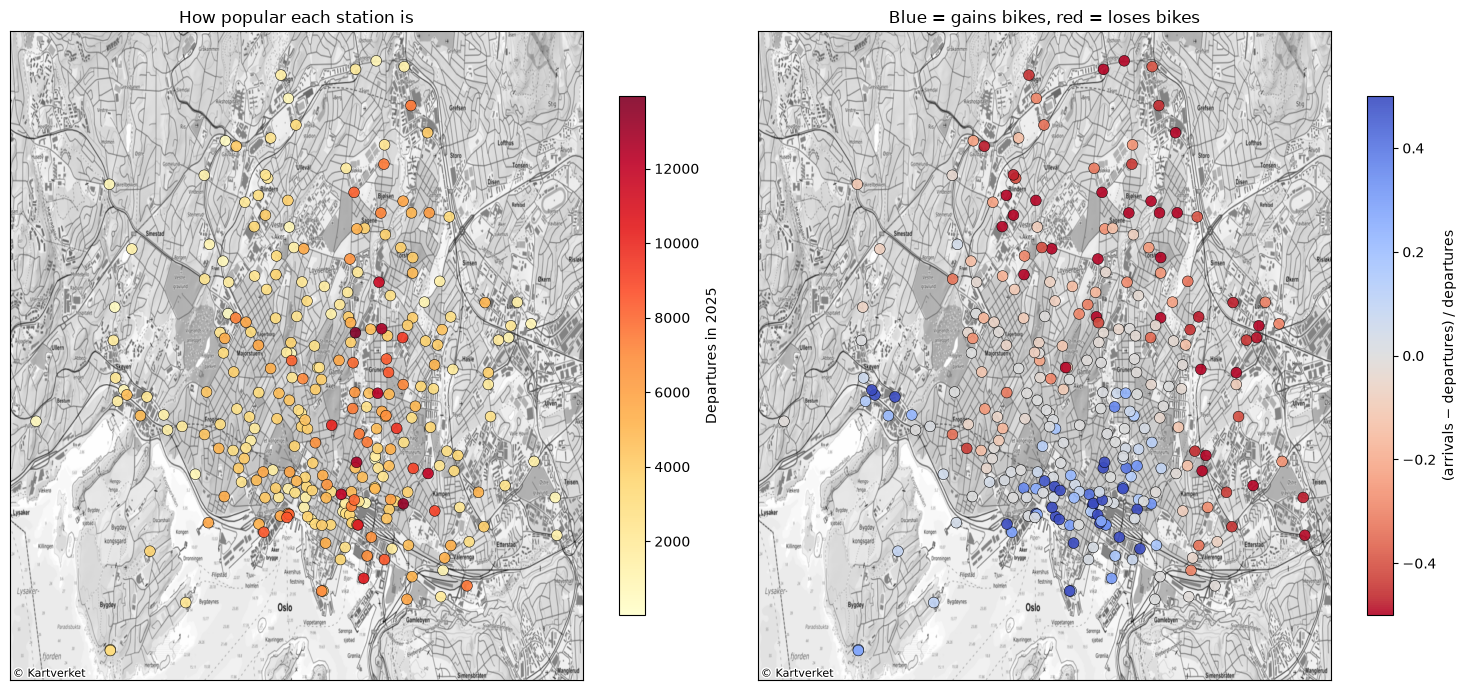

Stations that lose the most bikes:
                    name  total_departures  total_arrivals  net_flow
228                Hasle              3913             888 -0.773064
103   Torshovparken vest              4071            1027 -0.747728
200  Rolf Wickstrøms vei               962             286 -0.702703
192        Bjølsen mølle              5071            1536 -0.697101
160           Kirkeveien              3693            1176 -0.681560

Stations that gain the most bikes:
                 name  total_departures  total_arrivals  net_flow
176      Arkaden Nord              1715            5215  2.040816
148       Arkaden Sør              1286            3762  1.925350
129       Tøyenbekken              3899           11052  1.834573
49   Spikersuppa Vest              3437            7896  1.297352
107  Vaterlandsparken              5001           10868  1.173165


In [22]:
import contextily as ctx  # downloads map tiles from the internet
from matplotlib.colors import TwoSlopeNorm

# Free grey map from Kartverket (Norwegian Mapping Authority), CC BY 4.0, no API key needed
KARTVERKET_GREY = "https://cache.kartverket.no/v1/wmts/1.0.0/topograatone/default/webmercator/{z}/{y}/{x}.png"

stations["net_flow"] = (stations["total_arrivals"] - stations["total_departures"]) / stations["total_departures"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# Left: how popular each station is (biggest stations drawn last, so they end up on top)
by_size = stations.sort_values("total_departures")
points1 = ax1.scatter(
    by_size["lon"], by_size["lat"], c=by_size["total_departures"], cmap="YlOrRd",
    s=60, edgecolor="black", linewidth=0.4, alpha=0.9, zorder=2,
)
fig.colorbar(points1, ax=ax1, shrink=0.8, label="Departures in 2025")
ax1.set_title("How popular each station is")

# Right: does the station gain or lose bikes over the year?
points2 = ax2.scatter(
    stations["lon"], stations["lat"], c=stations["net_flow"].clip(-0.5, 0.5),
    cmap="coolwarm_r", norm=TwoSlopeNorm(vcenter=0, vmin=-0.5, vmax=0.5),
    s=60, edgecolor="black", linewidth=0.4, alpha=0.9, zorder=2,
)
fig.colorbar(points2, ax=ax2, shrink=0.8, label="(arrivals − departures) / departures")
ax2.set_title("Blue = gains bikes, red = loses bikes")

for ax in (ax1, ax2):
    ctx.add_basemap(ax, crs="EPSG:4326", source=KARTVERKET_GREY, attribution="© Kartverket", zoom=14)
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
fig.savefig(FIG_DIR / "01_station_map.png", dpi=150)
plt.show()

print("Stations that lose the most bikes:")
print(stations.nsmallest(5, "net_flow")[["name", "total_departures", "total_arrivals", "net_flow"]])
print("\nStations that gain the most bikes:")
print(stations.nlargest(5, "net_flow")[["name", "total_departures", "total_arrivals", "net_flow"]])

## 6. Station–hour table

For every station and every hour we count departures and arrivals. Hours without trips get 0.

Two rules to avoid filling the table with "fake" zeros:
- Only hours where the bike system was in use (at least one trip in the whole city).
- Only hours between the first and the last day a station was used (some stations open or close during the year).

In [16]:
trips["start_hour"] = trips["started_at"].dt.floor("h")
trips["end_hour"] = trips["ended_at"].dt.floor("h")

departures = trips.groupby(["start_station_id", "start_hour"]).size().rename("departures")
departures.index.names = ["station_id", "time"]

arrivals = trips.groupby(["end_station_id", "end_hour"]).size().rename("arrivals")
arrivals.index.names = ["station_id", "time"]

# All hours where at least one trip started somewhere in the city
open_hours = trips["start_hour"].drop_duplicates().sort_values()

all_rows = pd.MultiIndex.from_product([stations["station_id"], open_hours], names=["station_id", "time"])
station_hourly = pd.DataFrame(index=all_rows).join(departures).join(arrivals).fillna(0).reset_index()
station_hourly["departures"] = station_hourly["departures"].astype(int)
station_hourly["arrivals"] = station_hourly["arrivals"].astype(int)

# Keep only the period where each station was in use
first_day = trips.groupby("start_station_id")["start_hour"].min().dt.floor("D").rename("first_day")
last_day = trips.groupby("start_station_id")["start_hour"].max().dt.ceil("D").rename("last_day")
station_hourly = station_hourly.merge(first_day, left_on="station_id", right_index=True)
station_hourly = station_hourly.merge(last_day, left_on="station_id", right_index=True)
in_use = (station_hourly["time"] >= station_hourly["first_day"]) & (station_hourly["time"] < station_hourly["last_day"])
station_hourly = station_hourly[in_use].drop(columns=["first_day", "last_day"])

print("Rows:", len(station_hourly))
station_hourly.head()

Rows: 1852877


,station_id,time,departures,arrivals
2370,377,2025-04-30 03:00:00+00:00,0,0
2371,377,2025-04-30 04:00:00+00:00,0,0
2372,377,2025-04-30 05:00:00+00:00,0,0
2373,377,2025-04-30 06:00:00+00:00,0,0
2374,377,2025-04-30 07:00:00+00:00,0,0


### Add time features and weather

In [17]:
# Norwegian public holidays in 2025
holidays = pd.to_datetime([
    "2025-01-01", "2025-04-17", "2025-04-18", "2025-04-20", "2025-04-21",
    "2025-05-01", "2025-05-17", "2025-05-29", "2025-06-08", "2025-06-09",
    "2025-12-25", "2025-12-26",
])

local_time = station_hourly["time"].dt.tz_convert("Europe/Oslo")
station_hourly["date"] = local_time.dt.normalize().dt.tz_localize(None)
station_hourly["hour"] = local_time.dt.hour
station_hourly["weekday"] = local_time.dt.weekday  # 0 = Monday, 6 = Sunday
station_hourly["month"] = local_time.dt.month
station_hourly["is_holiday"] = station_hourly["date"].isin(holidays).astype(int)

weather_features = [
    "time", "temperature_2m", "relative_humidity_2m", "precipitation",
    "snow_depth", "cloud_cover", "wind_speed_10m",
]
station_hourly = station_hourly.merge(weather_hourly[weather_features], on="time", how="left")
station_hourly = station_hourly.merge(stations[["station_id", "lat", "lon"]], on="station_id", how="left")

print("Missing values per column:")
print(station_hourly.isna().sum())
station_hourly.head()

Missing values per column:
station_id              0
time                    0
departures              0
arrivals                0
date                    0
hour                    0
weekday                 0
month                   0
is_holiday              0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
snow_depth              0
cloud_cover             0
wind_speed_10m          0
lat                     0
lon                     0
dtype: int64


,station_id,time,departures,arrivals,date,hour,weekday,month,is_holiday,temperature_2m,relative_humidity_2m,precipitation,snow_depth,cloud_cover,wind_speed_10m,lat,lon
0,377,2025-04-30 03:00:00+00:00,0,0,2025-04-30,5,2,4,0,6.0,82,0.0,0.0,0,1.66,59.915667,10.777567
1,377,2025-04-30 04:00:00+00:00,0,0,2025-04-30,6,2,4,0,5.8,83,0.0,0.0,3,1.54,59.915667,10.777567
2,377,2025-04-30 05:00:00+00:00,0,0,2025-04-30,7,2,4,0,8.0,76,0.0,0.0,77,1.63,59.915667,10.777567
3,377,2025-04-30 06:00:00+00:00,0,0,2025-04-30,8,2,4,0,9.9,64,0.0,0.0,100,1.77,59.915667,10.777567
4,377,2025-04-30 07:00:00+00:00,0,0,2025-04-30,9,2,4,0,11.0,55,0.0,0.0,100,2.33,59.915667,10.777567


## 7. Save the tables

In [19]:
station_hourly.to_parquet(PROCESSED_DIR / "station_hourly.parquet", index=False)
stations.to_csv(PROCESSED_DIR / "stations.csv", index=False)
print("Saved", len(station_hourly), "station-hour rows and", len(stations), "stations")

Saved 1852877 station-hour rows and 272 stations
